# Villes de Belgique — la métadonnée dépend-elle de l'estimateur de densité ?

**Notebook miroir du [03 (Autriche)](03_austria_estimator_comparison.ipynb)**, même
structure et mêmes observables, appliqué au second dataset portant une *vraie population
de ville*. Les deux pays diffèrent nettement, ce qui est tout l'intérêt de la
comparaison.

**La question.** Les notebooks [01](01_metadata_generative_model.ipynb) et
[02](02_metadata_observables.ipynb) marquent le SP par la **densité locale**, estimée par
les k plus proches voisins. Mais le comptage de voisins dans un rayon fixe est tout aussi
légitime — et on a découvert qu'il ne donne pas le même Δγ (+0.15 avec k-NN, ≈ 0 avec le
rayon), malgré une corrélation de rang de 0.945 entre les deux estimateurs.

**Le design expérimental** (identique au 03) : populations attribuées par
**rank-matching** dans les deux cas — les vraies populations belges, appariées par rang
de densité. Ce choix garantit que :

- la **distribution** des populations est *exactement* celle des données (même loi de
  Zipf), donc **identique entre les deux cas** ;
- la **seule** différence entre les deux marquages est **quel nœud reçoit quelle
  population**, c'est-à-dire l'effet pur de l'estimateur.

**Pourquoi la Belgique** : avec l'Autriche, c'est l'un des deux seuls datasets portant une
vraie population de ville (Simplemaps) et non une densité WorldPop. N = 815, et Bruxelles
y pèse 9.7 % de la population nationale — contre 24.6 % pour Vienne en Autriche. Cette
**primatie urbaine bien plus faible** est la clé des écarts entre les deux pays.

Code : [`src/metadata_marks.py`](../src/metadata_marks.py).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent           # racine fake_world_paper_july_2026/
sys.path.insert(0, str(ROOT / "src"))
import synthese_utils as su
import metadata_marks as mm

# Palette Okabe-Ito : une teinte par ESTIMATEUR (les deux cas partagent le même
# rank-matching, donc la couleur ne code pas le mapping mais l'estimateur).
C = {"data": "#000000", "knn": "#0072B2", "rad": "#D55E00",
     "null": "#999999", "poisson": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

DATASET_NAME = "Belgium Cities"
ds = su.DATASETS[DATASET_NAME]
ld = su.load_dataset(ds)
xy_data, pop_data, geom = ld["xy_norm"], ld["pop_data"], ld["geom_norm"]
print(f"{DATASET_NAME} : N={ld['N_real']}, échelle={ld['scale_m']/1e3:.0f} km")
print(f"  population min/médiane/max = {pop_data.min():.0f} / "
      f"{np.median(pop_data):.0f} / {pop_data.max():.0f}  (Bruxelles)")
print(f"  part de la 1re ville = {100*pop_data.max()/pop_data.sum():.1f}% "
      f"(Autriche : 24.6 % pour Vienne)")
print(f"  gamma des noeuds = {ld['gamma_fit']:.3f}")

# Le nuage génératif : SP mixte calibré (fractal + fond aléatoire)
xy_sp = su.build_sp_mixture(ds, ld["gdf_edge"], ld["bounds"], geom,
                            ld["r_data"], ld["xi_data"],
                            N_target=ld["N_real"], seed=su.SEED)
print(f"  SP mixte : {len(xy_sp)} noeuds")

  N=815  échelle=272.8 km


  gamma_data=0.515  r0_norm=0.00390
Belgium Cities : N=815, échelle=273 km
  population min/médiane/max = 19 / 8277 / 1235192  (Bruxelles)
  part de la 1re ville = 9.7% (Autriche : 24.6 % pour Vienne)
  gamma des noeuds = 0.515


  SP mixte : 815 noeuds


## 1. Les deux estimateurs de densité locale

- **k-NN** : on cherche le rayon du **plus petit disque centré sur le nœud qui
  contient exactement k voisins** (k=10) — ce rayon est d_k(i), la distance au k-ième
  voisin. Une densité étant un nombre de points par unité de surface :

  $$\rho_k(i) = \frac{k}{\pi \, d_k(i)^2} \qquad \text{(k voisins ÷ l'aire du disque qui les contient juste)}$$

  Exemple : 10ᵉ voisin à 2 km → ρ ≈ 0.8 nœud/km² ; 10ᵉ voisin à 20 km → ρ ≈ 0.008,
  cent fois moins. D'où « l'inverse de la distance au k-ième voisin » (au carré).
  Valeur **continue** (d_k est une distance réelle, pratiquement jamais d'ex aequo) et
  **l'échelle s'adapte localement** : le rayon d'estimation *est* d_k(i) — petit en
  zone dense (résolution fine), grand en zone vide (moyenne sur une grande surface).
- **comptage à rayon fixe** : nombre de voisins dans un disque de rayon h **imposé,
  identique partout** (h = distance 10-NN médiane du nuage). Valeur **entière**, donc
  beaucoup d'ex aequo.

Seul le *classement* compte ici (le rank-matching n'utilise que lui), d'où le Spearman.

rayon h = 0.0419 (normalisé) = 11.4 km
Spearman(k-NN, rayon) = 0.945   <- les deux estimateurs semblent d'accord
ex aequo : k-NN 41/815 (5%) | rayon 766/815 (94%)
valeurs distinctes : k-NN 774 | rayon 49


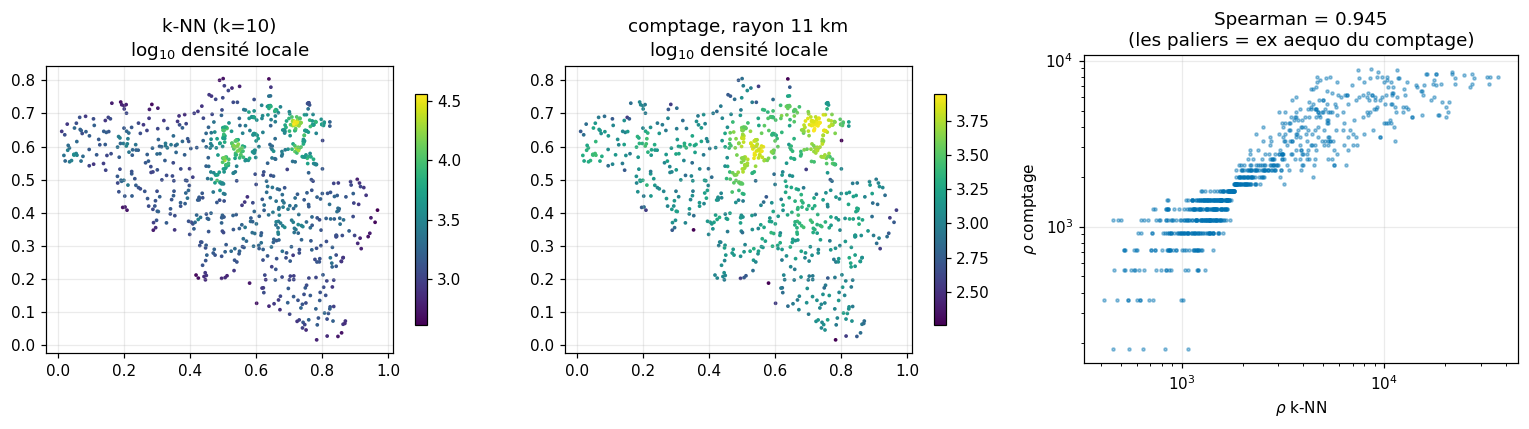

In [2]:
K_NN = 10
rho_knn = mm.local_density_knn(xy_sp, k=K_NN)
h = mm.default_radius(xy_sp, k=K_NN)
rho_rad = mm.local_density_radius(xy_sp, h)

rs = spearmanr(rho_knn, rho_rad).statistic
ties = lambda r: len(r) - len(np.unique(r))
print(f"rayon h = {h:.4f} (normalisé) = {h * ld['scale_m'] / 1e3:.1f} km")
print(f"Spearman(k-NN, rayon) = {rs:.3f}   <- les deux estimateurs semblent d'accord")
print(f"ex aequo : k-NN {ties(rho_knn)}/{len(rho_knn)} "
      f"({100*ties(rho_knn)/len(rho_knn):.0f}%) | "
      f"rayon {ties(rho_rad)}/{len(rho_rad)} ({100*ties(rho_rad)/len(rho_rad):.0f}%)")
print(f"valeurs distinctes : k-NN {len(np.unique(rho_knn))} | rayon {len(np.unique(rho_rad))}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, rho, ttl in [(axes[0], rho_knn, f"k-NN (k={K_NN})"),
                     (axes[1], rho_rad, f"comptage, rayon {h*ld['scale_m']/1e3:.0f} km")]:
    sc = ax.scatter(*xy_sp.T, s=6, c=np.log10(np.maximum(rho, rho[rho > 0].min())),
                    cmap="viridis", lw=0)
    ax.set_aspect("equal"); ax.set_title(f"{ttl}\nlog$_{{10}}$ densité locale")
    fig.colorbar(sc, ax=ax, shrink=0.75)
axes[2].loglog(rho_knn, np.maximum(rho_rad, rho_rad[rho_rad > 0].min()),
               ".", ms=4, alpha=0.4, c=C["knn"])
axes[2].set_xlabel("$\\rho$ k-NN"); axes[2].set_ylabel("$\\rho$ comptage")
axes[2].set_title(f"Spearman = {rs:.3f}\n(les paliers = ex aequo du comptage)")
fig.tight_layout(); plt.show()

## 2. Rank-matching : deux marquages, une seule distribution

On apparie les vraies populations belges (triées décroissantes) au classement de
densité : le nœud le plus dense reçoit Bruxelles, le second Anvers, etc. Fait une fois
avec chaque estimateur.

**Contrôle attendu** : exposant de Zipf *identique* aux données dans les deux cas —
la garantie que seul le placement diffère.

> **Note sur les ex aequo.** Le comptage produit des entiers, donc des ex aequo, que
> `pop_rank_matching` départage par ordre d'index (lequel suit la génération de l'arbre
> SP). Vérifié sur l'Autriche (notebook 03) : départager aléatoirement ne change rien
> (M_norm 2.793 ± 0.002), car les ex aequo se concentrent dans les zones peu denses
> alors que les grandes villes vont à des nœuds de densité *distincte*.

Contrôle — la distribution des populations est-elle bien identique ?
  Zipf : données 1.228 | k-NN 1.228 | rayon 1.228
  mêmes valeurs de population : True (k-NN), True (rayon)

Mais les deux marquages diffèrent : Spearman(pop_knn, pop_rad) = 0.943
  noeuds recevant une population différente : 813 / 815


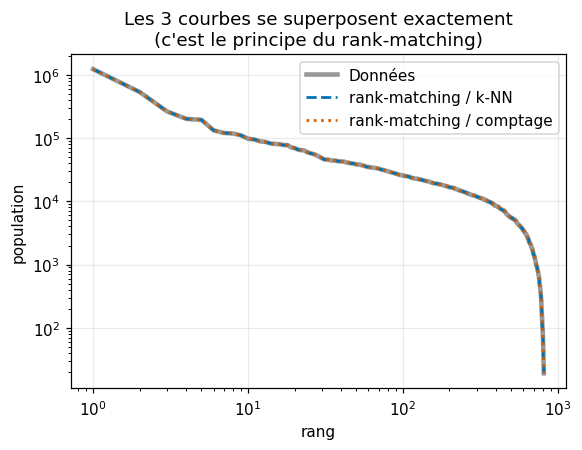

In [3]:
pop_knn = mm.pop_rank_matching(rho_knn, pop_data)   # marquage via k-NN
pop_rad = mm.pop_rank_matching(rho_rad, pop_data)   # marquage via comptage

print("Contrôle — la distribution des populations est-elle bien identique ?")
print(f"  Zipf : données {su.fit_zipf_exponent(pop_data):.3f} | "
      f"k-NN {su.fit_zipf_exponent(pop_knn):.3f} | rayon {su.fit_zipf_exponent(pop_rad):.3f}")
print(f"  mêmes valeurs de population : "
      f"{np.array_equal(np.sort(pop_knn), np.sort(pop_data))} (k-NN), "
      f"{np.array_equal(np.sort(pop_rad), np.sort(pop_data))} (rayon)")
print(f"\nMais les deux marquages diffèrent : Spearman(pop_knn, pop_rad) = "
      f"{spearmanr(pop_knn, pop_rad).statistic:.3f}")
print(f"  noeuds recevant une population différente : "
      f"{(pop_knn != pop_rad).sum()} / {len(pop_knn)}")

def ranksize(p):
    p = np.sort(np.asarray(p))[::-1]
    return np.arange(1, len(p) + 1), p

fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.loglog(*ranksize(pop_data), "-", c=C["data"], lw=3, alpha=0.4, label="Données")
ax.loglog(*ranksize(pop_knn), "--", c=C["knn"], lw=1.8, label="rank-matching / k-NN")
ax.loglog(*ranksize(pop_rad), ":", c=C["rad"], lw=1.8, label="rank-matching / comptage")
ax.set_xlabel("rang"); ax.set_ylabel("population")
ax.set_title("Les 3 courbes se superposent exactement\n(c'est le principe du rank-matching)")
ax.legend(); fig.tight_layout(); plt.show()

## 3. Où atterrissent les grandes villes ?

Même liste de populations dans les trois cartes ; seul change le nœud qui reçoit
chacune.

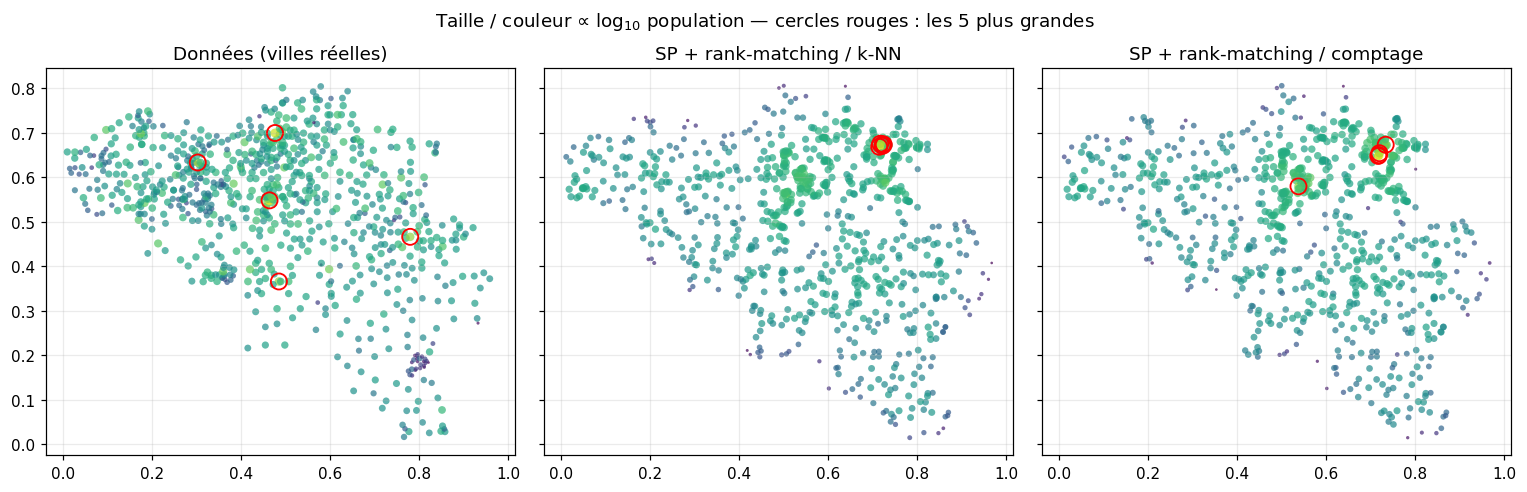

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, xy, p, ttl in [(axes[0], xy_data, pop_data, "Données (villes réelles)"),
                       (axes[1], xy_sp, pop_knn, "SP + rank-matching / k-NN"),
                       (axes[2], xy_sp, pop_rad, "SP + rank-matching / comptage")]:
    lp = np.log10(p)
    s = 3 + 34 * (lp - lp.min()) / (lp.max() - lp.min())
    ax.scatter(*xy.T, s=s, c=lp, cmap="viridis", alpha=0.7, lw=0)
    top = np.argsort(p)[::-1][:5]
    ax.scatter(*xy[top].T, s=110, facecolors="none", edgecolors="red", lw=1.2)
    ax.set_aspect("equal"); ax.set_title(ttl)
fig.suptitle("Taille / couleur ∝ log$_{10}$ population — cercles rouges : les 5 plus grandes")
fig.tight_layout(); plt.show()

## 4. Observable 1 — M(r) et sa version normalisée M_norm(r)

### La définition de départ

Pour chaque nœud *i*, on cumule la population de ses voisins situés à moins de *r* :

$$M_i(r) \;=\; \sum_{j\,:\,d_{ij} \le r} \mathrm{pop}_j$$

et on moyenne sur tous les nœuds → ⟨M(r)⟩. C'est une fonction **en escalier** : elle
saute à chaque voisin franchi et reste plate entre deux (le code l'évalue exactement par
recherche dichotomique ; interpoler linéairement, l'idiome naturel mais faux,
surestimerait M(r) jusqu'à ~30 % aux petits r).

### Pourquoi la pente D_M ne peut PAS mesurer le couplage

L'intuition « M(r) monte plus vite si les grosses populations sont agglomérées, donc sa
pente D_M détecte le couplage » est **fausse**, et on peut le démontrer. En intervertissant
les deux sommes — au lieu de demander « quelle population autour de *i* ? », on demande
« combien de nœuds *i* comptent *j* dans leur voisinage ? » — on obtient l'identité
**exacte** :

$$\langle M(r)\rangle \;=\; \underbrace{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle}_{\text{géométrie des points}} \;+\; \underbrace{\mathrm{Cov}\big(\mathrm{pop}_j,\, n_j(r)\big)}_{\text{couplage}}$$

où **n_j(r)** est le nombre de voisins du nœud *j* dans un rayon *r*, et ⟨N(r)⟩ = ⟨n(r)⟩
sa moyenne. Lecture des deux termes :

- le **premier** ne dépend **que des positions** (la population n'y entre que par sa
  moyenne) : c'est de la géométrie pure, identique que les marques soient bien placées
  ou mélangées au hasard ;
- le **second**, la covariance entre la population d'un nœud et son nombre de voisins,
  est le **seul** terme qui contient le couplage.

Or le premier terme **domine** et fixe la pente ; le second agit comme une correction
quasi *multiplicative* — il décale la courbe **verticalement** sans la faire pivoter. La
pente est donc essentiellement aveugle au couplage. Vérification numérique (30
permutations des marques) :

| | D_M |
|---|---|
| Données | 2.31 |
| Null (marques mélangées) | 2.26 ± 0.13 → **0.4σ : indiscernable** |
| Poisson (positions changées) | 2.18 |

⇒ On garde D_M comme descripteur de la **géométrie des points**, jamais comme preuve de
couplage. (Attention : M(r) lui-même *dépend* bien du placement des marques — l'amplitude
change d'un facteur ~1.6, à 4.8σ. C'est le **résumé par la pente** qui jette
l'information, pas l'observable.)

### La correction : normaliser par la géométrie

Puisque le terme parasite est ⟨pop⟩·⟨N(r)⟩, il suffit de diviser par lui :

$$M_{\mathrm{norm}}(r) \;=\; \frac{\langle M(r)\rangle}{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle} \;=\; 1 \;+\; \frac{\mathrm{Cov}\big(\mathrm{pop}_j,\, n_j(r)\big)}{\langle \mathrm{pop}\rangle \cdot \langle N(r)\rangle}$$

La géométrie disparaît, il ne reste que le couplage, sous une forme directement lisible :

- **M_norm(r) = 1** ⇔ covariance nulle ⇔ **aucun couplage**. Ce n'est pas un réglage
  empirique : c'est la valeur du null **par construction**, puisque permuter les marques
  rend pop_j et n_j(r) indépendants, donc E[⟨M(r)⟩] = ⟨pop⟩·⟨N(r)⟩ exactement.
- **M_norm(r) > 1** : les nœuds sont entourés de *plus* de population qu'attendu vu leur
  nombre de voisins → les fortes populations se regroupent, à l'échelle *r*.
- **M_norm(r) < 1** : elles s'évitent.

L'écart à 1 **est** le couplage — d'où une échelle absolue et interprétable, là où D_M
n'offrait qu'une comparaison relative sans signification.

> **Pourquoi le null est moyenné sur 30 permutations.** Un seul tirage est très bruité
> quand la distribution des marques a une queue lourde (loi de Zipf) : une permutation
> place la capitale — 10 à 25 % de la population nationale à elle seule — n'importe où,
> et cela suffit à déplacer toute la courbe. La bande grise des figures est l'écart-type
> sur ces 30 tirages.

### Et pourquoi ne pas tracer la covariance seule ?

Puisque Cov(pop_j, n_j(r)) *est* le couplage, pourquoi normaliser ? Parce que
**M_norm − 1 n'est que la covariance rééchelonnée** — même information, mais :

1. Cov est **dimensionnée** (habitants × voisins) : compter les populations en milliers
   la diviserait par 1000 sans rien changer de physique ;
2. Cov n'est **pas comparable entre systèmes** : son pic vaut 840 561 en Belgique contre
   100 387 en Autriche (8.4×), mais 3.9× de cet écart ne sont que la taille moyenne des
   villes (15.7 k contre 4.0 k) — un artefact du découpage administratif, pas du
   couplage. M_norm (1.74 vs 1.16) n'a pas ce biais ;
3. M_norm suit la **convention du domaine** (ξ = DD/RR − 1, k_mm = ⟨m_i m_j⟩/⟨m⟩²).

En contrepartie, M_norm vaut 0/0 aux petits r et y devient bruitée, là où la covariance
tend proprement vers 0. Le **3ᵉ panneau** de la figure trace donc la covariance brute :
M_norm pour comparer et publier, covariance pour lire les petites échelles.

cas                                 D_M   M_norm au pic
Données                            2.31    1.74 à r=0.0055 (1.5 km)
SP + rank-matching / k-NN          1.46    3.13 à r=0.0119 (3.2 km)
SP + rank-matching / comptage      1.51    2.39 à r=0.0026 (0.7 km)
Données, marques mélangées         2.28    1.10 à r=0.0033 (0.9 km)
Poisson + marques données          2.18    1.22 à r=0.0119 (3.2 km)

D_M    : données 2.310 vs null 2.260 ± 0.132  -> 0.4 sigma (non discriminant, comme attendu)
M_norm : null plat à 1.01


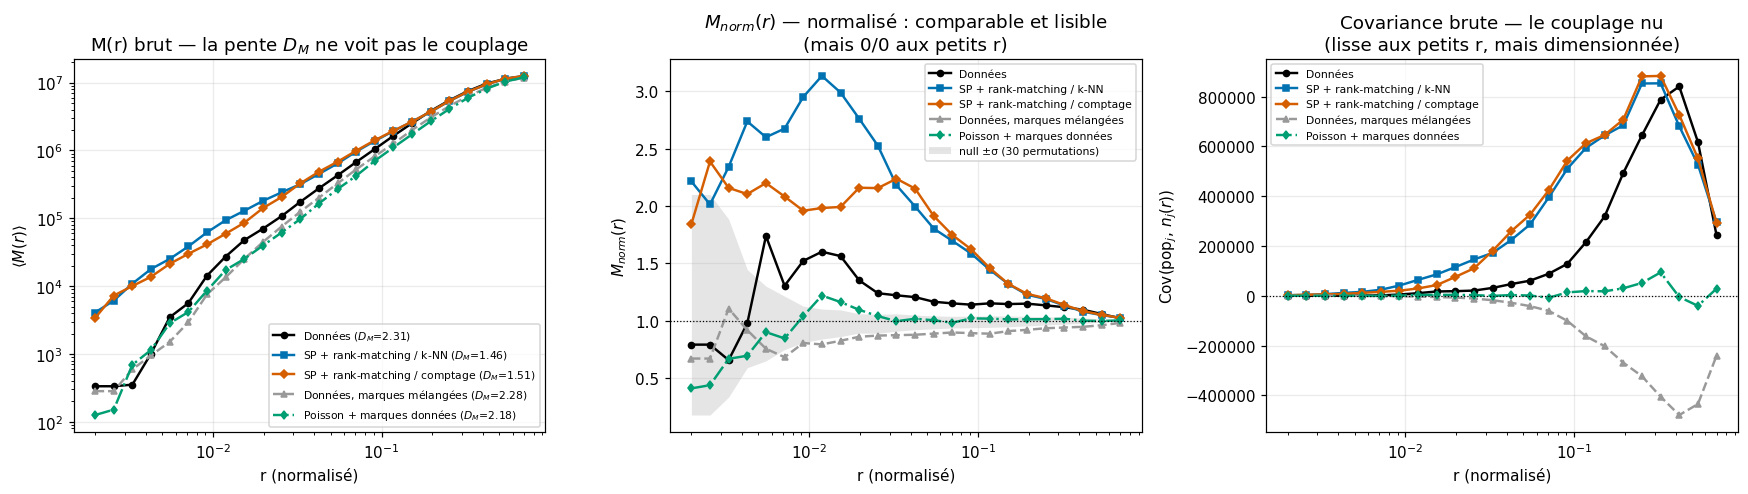

In [5]:
r_grid = np.logspace(np.log10(2e-3), np.log10(0.7), 24)
xy_pois = su.simulate_poisson(len(xy_data), geom, seed=1)
rng = np.random.default_rng(0)

cases = {
    "Données":                       (xy_data, pop_data,             C["data"], "o-"),
    "SP + rank-matching / k-NN":     (xy_sp,   pop_knn,              C["knn"],  "s-"),
    "SP + rank-matching / comptage": (xy_sp,   pop_rad,              C["rad"],  "D-"),
    "Données, marques mélangées":    (xy_data, rng.permutation(pop_data), C["null"], "^--"),
    "Poisson + marques données":     (xy_pois, pop_data,             C["poisson"], "d-."),
}
M_prof, M_norm, COV, DM, pk = {}, {}, {}, {}, {}
for k, (xy, p, *_) in cases.items():
    mn, M, N = mm.normalized_population_profile(xy, p, r_grid)
    M_prof[k], M_norm[k] = M, mn
    COV[k] = mm.covariance_profile(M, N, p)      # couplage brut, non normalisé
    DM[k] = mm.mass_dimension(r_grid, M, a=1, b=16)
    i = int(np.nanargmax(mn[1:16]) + 1)
    pk[k] = (float(mn[i]), float(r_grid[i]))

null_m, null_s, dm_null, dm_null_s = mm.shuffled_null_profile(
    xy_data, pop_data, r_grid, n_shuffle=30, seed=0)

print(f"{'cas':32s} {'D_M':>6s}   M_norm au pic")
for k in cases:
    print(f"{k:32s} {DM[k]:6.2f}   {pk[k][0]:5.2f} à r={pk[k][1]:.4f} "
          f"({pk[k][1]*ld['scale_m']/1e3:.1f} km)")
print(f"\nD_M    : données {DM['Données']:.3f} vs null {dm_null:.3f} ± {dm_null_s:.3f}"
      f"  -> {abs(DM['Données']-dm_null)/dm_null_s:.1f} sigma (non discriminant, comme attendu)")
print(f"M_norm : null plat à {np.nanmean(null_m):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for k, (xy, p, c, st) in cases.items():
    axes[0].loglog(r_grid, M_prof[k], st, ms=4, c=c, lw=1.6,
                   label=f"{k} ($D_M$={DM[k]:.2f})")
    axes[1].semilogx(r_grid, M_norm[k], st, ms=4, c=c, lw=1.6, label=k)
    axes[2].semilogx(r_grid, COV[k], st, ms=4, c=c, lw=1.6, label=k)
axes[0].set_xlabel("r (normalisé)")
axes[0].set_ylabel("$\\langle M(r) \\rangle$")
axes[0].set_title("M(r) brut — la pente $D_M$ ne voit pas le couplage")
axes[0].legend(fontsize=7)

axes[1].fill_between(r_grid, null_m - null_s, null_m + null_s, color=C["null"],
                     alpha=0.25, lw=0, label="null ±σ (30 permutations)")
axes[1].axhline(1, c="k", lw=0.8, ls=":")
axes[1].set_xlabel("r (normalisé)")
axes[1].set_ylabel("$M_{norm}(r)$")
axes[1].set_title("$M_{norm}(r)$ — normalisé : comparable et lisible\n(mais 0/0 aux petits r)")
axes[1].legend(fontsize=7)

axes[2].axhline(0, c="k", lw=0.8, ls=":")
axes[2].set_xlabel("r (normalisé)")
axes[2].set_ylabel("$\\mathrm{Cov}(\\mathrm{pop}_j,\\, n_j(r))$")
axes[2].set_title("Covariance brute — le couplage nu\n(lisse aux petits r, mais dimensionnée)")
axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

## 5. Observable 2 — la « 2PCF des gens »

On pondère chaque paire par le produit des populations (équivalent à superposer sur
chaque nœud un nombre de points ∝ sa population) : la 2PCF *des habitants* plutôt que
*des villes*.

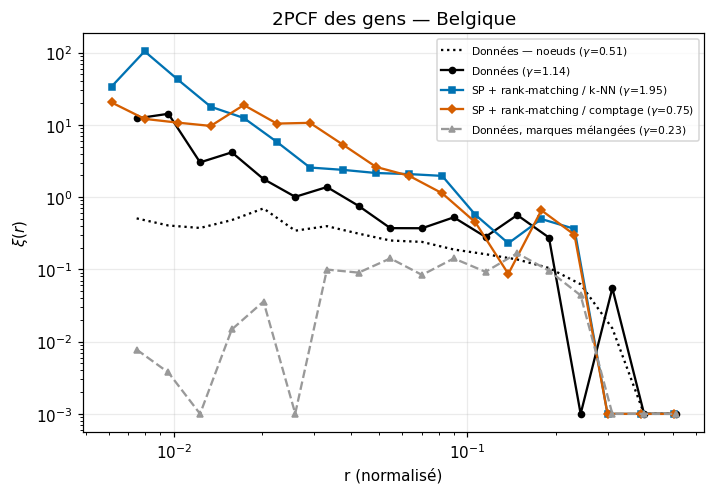

gamma des noeuds (données)      : 0.515
gamma_people — Données                        : 1.140
gamma_people — SP + rank-matching / k-NN      : 1.950
gamma_people — SP + rank-matching / comptage  : 0.748
gamma_people — Données, marques mélangées     : 0.232

-> les données tombent ENTRE les deux estimateurs : le k-NN dépasse la cible,
   le comptage reste en dessous. Le choix de l'estimateur décide du signe de l'erreur.


In [6]:
people = {}
for k in cases:
    if k == "Poisson + marques données":
        continue                                  # peu informatif ici
    xy, p, *_ = cases[k]
    people[k] = mm.compute_2pcf_people(xy, p, geom)

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.loglog(ld["r_data"], np.clip(ld["xi_data"], 1e-3, None), ":", c=C["data"],
          lw=1.5, label=f"Données — noeuds ($\\gamma$={ld['gamma_fit']:.2f})")
gammas = {}
for k, (r, xi) in people.items():
    g, _ = su.fit_powerlaw_norm(r, xi)
    gammas[k] = g
    _, _, c, st = cases[k]
    ax.loglog(r, np.clip(xi, 1e-3, None), st, ms=4, c=c,
              label=f"{k} ($\\gamma$={g:.2f})" if g is not None else k)
ax.set_xlabel("r (normalisé)"); ax.set_ylabel("$\\xi(r)$")
ax.set_title("2PCF des gens — Belgique")
ax.legend(fontsize=7); fig.tight_layout(); plt.show()

print(f"gamma des noeuds (données)      : {ld['gamma_fit']:.3f}")
for k, g in gammas.items():
    print(f"gamma_people — {k:30s} : {g:.3f}")
print("\n-> les données tombent ENTRE les deux estimateurs : le k-NN dépasse la cible,")
print("   le comptage reste en dessous. Le choix de l'estimateur décide du signe de l'erreur.")

### Contrôle — d'où vient γ_people ? (test de la primatie urbaine)

**Ce qu'est la primatie urbaine.** C'est le degré de domination de la plus grande ville
d'un pays sur toutes les autres. La notion vient de la géographie urbaine (Jefferson,
*The Law of the Primate City*, 1939) : une **ville primatiale** n'est pas seulement la
plus grande, elle est *disproportionnellement* grande — plus grande que ce que la
régularité rang-taille du reste du système laisse prévoir. Vienne (2.2 M) et Bruxelles
(1.2 M) sont toutes deux primatiales à ce sens strict, mais à des degrés très
différents.

**Comment on la mesure.** Plusieurs indices classiques, tous calculés dans la cellule
suivante :
- **indice à deux villes** P₁/P₂ — le rapport de la 1ʳᵉ à la 2ᵈᵉ ville (Jefferson) ;
- **indice à quatre villes** P₁/(P₁+P₂+P₃+P₄) — 0.25 = pas de primatie, 1 = ville unique ;
- **part de P₁ dans la population totale** ;
- et le test strict : **P₁ observée vs P₁ prédite** par la loi rang-taille ajustée sur
  les rangs 2 à 50 puis extrapolée au rang 1. Un ratio ≫ 1 signe la primatie.

> ⚠️ **L'exposant de Zipf ne mesure PAS la primatie.** Il décrit la pente de *toute* la
> distribution, alors que la primatie est un décrochage *au sommet*. Les deux pays le
> montrent : la Belgique a un Zipf plus **raide** (1.23 contre 1.02) et pourtant une
> primatie bien **plus faible**. Une ville primatiale est un point *au-dessus* de la
> droite de Zipf, pas une pente différente.

**Pourquoi ça compte pour ξ_people.** La « 2PCF des gens » pondère chaque paire (i, j)
par le **produit des populations** p_i·p_j. Une ville qui concentre une grosse part de
la population capte donc une part énorme du poids total : la cellule suivante montre que
les paires impliquant la seule 1ʳᵉ ville pèsent **39.6 %** de ξ_people en Autriche
(contre 17.7 % en Belgique). Autrement dit, ξ_people n'est pas une statistique sur le
système : c'est en grande partie une statistique **sur une poignée de villes**.

**Le test.** C'est une analyse de sensibilité par retrait du sommet (une jackknife sur
la queue haute) : on retire les *n* plus grandes villes, on recalcule ξ_people sur le
reste, et on refait le fit. On balaie n = 0, 1, 5, 20.

**Comment le lire.**
- Si γ_people **bouge fortement** en retirant *une seule* ville sur plusieurs milliers,
  la statistique est dominée par cette ville → forte variance, descripteur fragile.
- S'il **converge vers γ_nœuds**, c'est que tout l'écart entre « 2PCF des gens » et
  « 2PCF des villes » était porté par le sommet de la distribution, et non par un
  couplage population↔position réparti sur l'ensemble du système.
- Le **sens** du déplacement dit où siège la ville dominante : une ville centrale,
  entourée d'autres grandes villes, peuple les petites distances et **raidit** la courbe ;
  une ville isolée étale ses paires sur toutes les distances et l'**aplatit**.

Les deux pays sont tracés ensemble ci-dessous pour la comparaison ; le même test figure au [notebook 03](03_austria_estimator_comparison.ipynb).

In [7]:
# Indices de primatie et poids des paires dans xi_people
print(f"{'':30s} {'Belgique':>10s} {'Autriche':>10s}")
prim = {}
for name in ("Belgium Cities", "Austria Cities"):
    p = np.sort(su.load_dataset(su.DATASETS[name], verbose=False)["pop_data"])[::-1]
    # P1 prédite par la loi rang-taille ajustée SANS elle (rangs 2..50)
    coef = np.polyfit(np.log(np.arange(2, 51)), np.log(p[1:50]), 1)
    p1_pred = np.exp(np.polyval(coef, np.log(1)))
    # poids des paires impliquant P1 dans xi_people (pondération p_i*p_j)
    w_tot = p.sum()**2 - (p**2).sum()          # = somme des p_i*p_j sur i != j
    w_p1 = 2 * p[0] * p[1:].sum()
    prim[name] = dict(p1_p2=p[0]/p[1], p1_4=p[0]/p[:4].sum(),
                      share=100*p[0]/p.sum(), zipf=su.fit_zipf_exponent(p),
                      ratio_pred=p[0]/p1_pred, w_p1=100*w_p1/w_tot)

for k, lbl, f in [("p1_p2", "P1/P2 (indice 2 villes)", "{:10.2f}"),
                  ("p1_4", "P1/(P1+P2+P3+P4)", "{:10.2f}"),
                  ("share", "part de P1 dans le total (%)", "{:10.1f}"),
                  ("zipf", "exposant de Zipf", "{:10.2f}"),
                  ("ratio_pred", "P1 observée / P1 predite", "{:10.2f}"),
                  ("w_p1", "poids des paires avec P1 (%)", "{:10.1f}")]:
    print(f"{lbl:30s} " + f.format(prim['Belgium Cities'][k])
          + " " + f.format(prim['Austria Cities'][k]))
print("\n-> Zipf plus RAIDE en Belgique (1.23 vs 1.02) mais primatie plus FAIBLE :")
print("   l'exposant de Zipf ne mesure pas la primatie (décrochage du sommet).")
print("-> ratio > 1.5 = ville primatiale au sens strict : les deux le sont (2.2 et 3.6).")
print("-> en Autriche, 40 % du poids de xi_people vient des paires impliquant Vienne")
print("   SEULE (1 ville sur 2253) : la statistique porte sur une poignee de villes.")

                                 Belgique   Autriche


P1/P2 (indice 2 villes)              2.30       7.60
P1/(P1+P2+P3+P4)                     0.55       0.76
part de P1 dans le total (%)          9.7       24.6
exposant de Zipf                     1.23       1.02
P1 observée / P1 predite             2.20       3.55
poids des paires avec P1 (%)         17.7       39.6

-> Zipf plus RAIDE en Belgique (1.23 vs 1.02) mais primatie plus FAIBLE :
   l'exposant de Zipf ne mesure pas la primatie (décrochage du sommet).
-> ratio > 1.5 = ville primatiale au sens strict : les deux le sont (2.2 et 3.6).
-> en Autriche, 40 % du poids de xi_people vient des paires impliquant Vienne
   SEULE (1 ville sur 2253) : la statistique porte sur une poignee de villes.


                 Belgique   Autriche   (gamma_people)


toutes              1.140      0.114
sans top-1          0.783      0.534
sans top-5          0.693      0.601
sans top-20         0.445      0.607
gamma_noeuds        0.515      0.494
part 1re ville       9.7%      24.6%


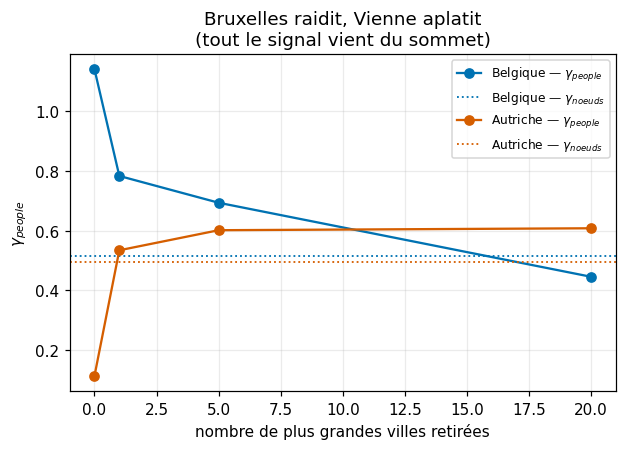

In [8]:
print(f"{'':14s} {'Belgique':>10s} {'Autriche':>10s}   (gamma_people)")
res_drop = {}
for name in ("Belgium Cities", "Austria Cities"):
    ld_i = su.load_dataset(su.DATASETS[name], verbose=False)
    p_i, xy_i, geom_i = ld_i["pop_data"], ld_i["xy_norm"], ld_i["geom_norm"]
    vals = {}
    for drop in (0, 1, 5, 20):
        keep = np.argsort(p_i)[::-1][drop:]
        r_i, xi_i = mm.compute_2pcf_people(xy_i[keep], p_i[keep], geom_i)
        g_i, _ = su.fit_powerlaw_norm(r_i, xi_i)
        vals[drop] = g_i
    vals["gamma_noeuds"] = ld_i["gamma_fit"]
    vals["part_1re_ville"] = 100 * p_i.max() / p_i.sum()
    res_drop[name] = vals

for drop, lbl in [(0, "toutes"), (1, "sans top-1"), (5, "sans top-5"), (20, "sans top-20")]:
    print(f"{lbl:14s} {res_drop['Belgium Cities'][drop]:10.3f} "
          f"{res_drop['Austria Cities'][drop]:10.3f}")
print(f"{'gamma_noeuds':14s} {res_drop['Belgium Cities']['gamma_noeuds']:10.3f} "
      f"{res_drop['Austria Cities']['gamma_noeuds']:10.3f}")
print(f"{'part 1re ville':14s} {res_drop['Belgium Cities']['part_1re_ville']:9.1f}% "
      f"{res_drop['Austria Cities']['part_1re_ville']:9.1f}%")

fig, ax = plt.subplots(figsize=(5.8, 4.2))
drops = [0, 1, 5, 20]
for name, c, lbl in [("Belgium Cities", C["knn"], "Belgique"),
                     ("Austria Cities", C["rad"], "Autriche")]:
    ax.plot(drops, [res_drop[name][d] for d in drops], "o-", c=c,
            label=f"{lbl} — $\\gamma_{{people}}$")
    ax.axhline(res_drop[name]["gamma_noeuds"], c=c, ls=":", lw=1.2,
               label=f"{lbl} — $\\gamma_{{noeuds}}$")
ax.set_xlabel("nombre de plus grandes villes retirées")
ax.set_ylabel("$\\gamma_{people}$")
ax.set_title("Bruxelles raidit, Vienne aplatit\n(tout le signal vient du sommet)")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

In [9]:
rows = []
for k in cases:
    rows.append(dict(observable="D_M [non discriminant]", cas=k, valeur=round(DM[k], 3)))
for k in cases:
    rows.append(dict(observable="M_norm au pic (1 = aucun couplage)", cas=k,
                     valeur=round(pk[k][0], 3)))
for k, g in gammas.items():
    rows.append(dict(observable="gamma_people", cas=k,
                     valeur=(round(g, 3) if g is not None else None)))
rows.append(dict(observable="gamma_noeuds", cas="Données",
                 valeur=round(ld["gamma_fit"], 3)))
df = pd.DataFrame(rows)
out_csv = ROOT / "out" / "04_belgium_estimator_comparison.csv"
df.to_csv(out_csv, index=False)
print(df.to_string(index=False))
print("->", out_csv)

                        observable                           cas  valeur
            D_M [non discriminant]                       Données   2.310
            D_M [non discriminant]     SP + rank-matching / k-NN   1.458
            D_M [non discriminant] SP + rank-matching / comptage   1.511
            D_M [non discriminant]    Données, marques mélangées   2.276
            D_M [non discriminant]     Poisson + marques données   2.179
M_norm au pic (1 = aucun couplage)                       Données   1.738
M_norm au pic (1 = aucun couplage)     SP + rank-matching / k-NN   3.134
M_norm au pic (1 = aucun couplage) SP + rank-matching / comptage   2.388
M_norm au pic (1 = aucun couplage)    Données, marques mélangées   1.104
M_norm au pic (1 = aucun couplage)     Poisson + marques données   1.219
                      gamma_people                       Données   1.140
                      gamma_people     SP + rank-matching / k-NN   1.950
                      gamma_people SP + rank-matchi

## Lecture des résultats — et comparaison à l'Autriche

| | M_norm au pic | γ_people |
|---|---|---|
| **Données Belgique** | **1.74** | **1.14** |
| SP, rank-matching / k-NN | 3.13 | 1.95 |
| SP, rank-matching / comptage | 2.39 | 0.75 |
| Null (marques mélangées) | 1.10 | 0.23 |
| *(rappel Autriche : données)* | *1.17* | *0.11* |
| *(rappel Autriche : k-NN / comptage)* | *6.99 / 2.79* | *0.60 / 1.00* |

**1. L'effet de l'estimateur est réel, mais bien plus modéré qu'en Autriche.** Sur
M_norm, le rapport k-NN/comptage vaut **1.3** en Belgique (3.13 vs 2.39) contre **2.5**
en Autriche (6.99 vs 2.79). Les deux marquages portent pourtant la même distribution de
populations : seul change le nœud qui reçoit chaque valeur.

**2. Mais sur γ_people, l'estimateur décide du *signe de l'erreur*.** Les données
(1.14) tombent **entre** les deux estimateurs : le k-NN dépasse largement (1.95), le
comptage reste en dessous (0.75). Autrement dit, selon l'estimateur choisi on conclurait
que le SP sur-couple ou qu'il sous-couple — sur le *même* nuage, avec les *mêmes*
populations. C'est l'illustration la plus nette que **le choix de l'estimateur est une
décision de modélisation**, pas un détail d'implémentation, et que la corrélation de
rang de 0.945 entre les deux ne protège de rien.

**3. La Belgique est bien mieux reproduite que l'Autriche.** Sur M_norm, le SP
sur-couple d'un facteur ≈ 1.8 (3.13 contre 1.74) là où l'Autriche atteint ≈ 6
(6.99 contre 1.16). Le couplage empirique belge est lui-même plus fort (1.74 contre
1.17), donc plus facile à atteindre pour un modèle qui, par construction, couple
fortement.

**4. Bruxelles raidit, Vienne aplatit.** Le test de primatie le montre : retirer
Bruxelles (9.7 % de la population) fait *baisser* γ_people (1.14 → 0.78), alors que
retirer Vienne (24.6 %) le fait *monter* (0.11 → 0.53). Bruxelles est centrale et
entourée d'autres grandes villes, donc ses paires pondérées peuplent les petites
distances et raidissent la courbe ; Vienne est isolée à l'est, ses paires s'étalent sur
toutes les distances et l'aplatissent. Dans les deux pays, **sans les plus grandes
villes γ_people ≈ γ_nœuds** : tout le signal de ξ_people vient du sommet de la
distribution des tailles.

**Ce que la paire Belgique/Autriche établit**
- Le couplage empirique **varie fortement d'un pays à l'autre** (M_norm 1.74 vs 1.17) :
  n'attendre aucune constante universelle, et se méfier d'un modèle calibré sur un seul
  système.
- ξ_people est une statistique **à forte variance**, pilotée par quelques villes et
  sensible à la primatie urbaine ; elle ne peut pas servir seule de critère de validation.
- Le sur-couplage du SP est **systématique mais d'ampleur variable** (≈ 1.8× ici, ≈ 6×
  en Autriche) — cohérent avec la cause identifiée au notebook 02 : le modèle fait de la
  population une fonction *déterministe* de la densité, alors que la relation empirique
  est bruitée. Un mapping stochastique reste la piste à tester.
- Les 7 autres datasets ne portent qu'une **densité WorldPop** et non une population de
  ville : ils ne permettent pas ce protocole tel quel.